<a href="https://colab.research.google.com/github/cacender10/yusuf/blob/main/Stroke_Prediction_Colab10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("Libraries imported successfully")

pandas: 2.2.3
numpy: 2.4.6
scikit-learn: 1.6.1
Libraries imported successfully


In [ ]:
from google.colab import files
uploaded = files.upload()          # choose healthcare-dataset-stroke-data.csv

df = pd.read_csv(list(uploaded.keys())[0])
print("Shape (rows, columns):", df.shape)
df.head()

Saving healthcare-dataset-stroke-data.csv to healthcare-dataset-stroke-data.csv
Shape (rows, columns): (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [ ]:
print("Missing values per column (BEFORE):")
print(df.isnull().sum())

# Save 'before' numbers for the M2 comparison later
bmi_missing_before = int(df['bmi'].isnull().sum())
dups_before = int(df.duplicated().sum())
gender_other_before = int((df['gender'] == 'Other').sum())
stroke_counts_before = df['stroke'].value_counts()
stroke_pct_before = df['stroke'].value_counts(normalize=True) * 100

print("\nDuplicate rows:", dups_before)
print("Rows with gender = 'Other':", gender_other_before)

Missing values per column (BEFORE):
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Duplicate rows: 0
Rows with gender = 'Other': 1


Stroke class counts (BEFORE):
stroke
0    4861
1     249
Name: count, dtype: int64

Percentages:
stroke
0    95.13
1     4.87
Name: proportion, dtype: float64


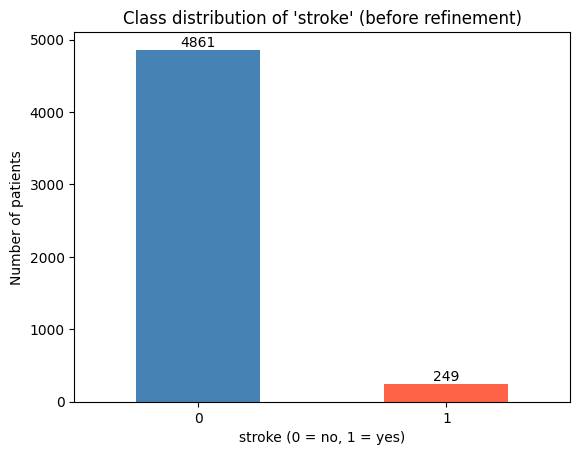

In [ ]:
print("Stroke class counts (BEFORE):")
print(stroke_counts_before)
print("\nPercentages:")
print(stroke_pct_before.round(2))

ax = stroke_counts_before.plot(kind='bar', color=['steelblue', 'tomato'])
plt.title("Class distribution of 'stroke' (before refinement)")
plt.xlabel("stroke (0 = no, 1 = yes)")
plt.ylabel("Number of patients")
plt.xticks(rotation=0)
for i, v in enumerate(stroke_counts_before):
    ax.text(i, v + 40, str(v), ha='center')
plt.show()

In [ ]:
df_clean = df.copy()

# 1. Drop the id column (no predictive value)
df_clean = df_clean.drop(columns=['id'])

# 2. Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# 3. Remove the single 'Other' gender record (too rare to learn from)
df_clean = df_clean[df_clean['gender'] != 'Other']

# 4. Fill missing bmi with the MEDIAN (bmi is right-skewed, median is robust)
median_bmi = df_clean['bmi'].median()
df_clean['bmi'] = df_clean['bmi'].fillna(median_bmi)

print("Median bmi used for filling:", round(median_bmi, 2))
print("Missing values AFTER cleaning:")
print(df_clean.isnull().sum())
print("\nNew shape:", df_clean.shape)

Median bmi used for filling: 28.1
Missing values AFTER cleaning:
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

New shape: (5109, 11)


In [ ]:
df_enc = df_clean.copy()

# Binary columns -> 0/1
df_enc['gender'] = df_enc['gender'].map({'Male': 0, 'Female': 1})
df_enc['ever_married'] = df_enc['ever_married'].map({'No': 0, 'Yes': 1})
df_enc['Residence_type'] = df_enc['Residence_type'].map({'Rural': 0, 'Urban': 1})

# Multi-category columns -> one-hot encoding
df_enc = pd.get_dummies(df_enc, columns=['work_type', 'smoking_status'],
                        drop_first=True, dtype=int)

print("Any text columns left?", df_enc.select_dtypes(include='object').columns.tolist())
df_enc.head()

Any text columns left? []


,gender,age,hypertension,heart_disease,ever_married,Residence_type,avg_glucose_level,bmi,stroke,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,0,67.0,0,1,1,1,228.69,36.6,1,0,1,0,0,1,0,0
1,1,61.0,0,0,1,0,202.21,28.1,1,0,0,1,0,0,1,0
2,0,80.0,0,1,1,0,105.92,32.5,1,0,1,0,0,0,1,0
3,1,49.0,0,0,1,1,171.23,34.4,1,0,1,0,0,0,0,1
4,1,79.0,1,0,1,0,174.12,24.0,1,0,0,1,0,0,1,0


In [ ]:
X = df_enc.drop(columns=['stroke'])
y = df_enc['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("X_train:", X_train.shape, " X_test:", X_test.shape)
print("y_train:", y_train.shape, " y_test:", y_test.shape)
print("\nStroke % in training set:", round(y_train.mean() * 100, 2))
print("Stroke % in testing set: ", round(y_test.mean() * 100, 2))

X_train: (4087, 15)  X_test: (1022, 15)
y_train: (4087,)  y_test: (1022,)

Stroke % in training set: 4.87
Stroke % in testing set:  4.89


In [ ]:
num_cols = ['age', 'avg_glucose_level', 'bmi']

print("BEFORE scaling (training data):")
display(X_train[num_cols].describe().round(2))

scaler = StandardScaler()
X_train_s = X_train.copy()
X_test_s = X_test.copy()
X_train_s[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit on training only
X_test_s[num_cols] = scaler.transform(X_test[num_cols])         # apply to test

print("AFTER scaling (training data):")
display(X_train_s[num_cols].describe().round(2))

BEFORE scaling (training data):


,age,avg_glucose_level,bmi
count,4087.00,4087.00,4087.00
mean,43.26,105.90,28.85
std,22.64,44.68,7.74
min,0.08,55.22,10.30
25%,25.00,77.46,23.75
50%,45.00,91.89,28.10
75%,61.00,114.04,32.80
max,82.00,271.74,97.60


AFTER scaling (training data):


,age,avg_glucose_level,bmi
count,4087.00,4087.00,4087.00
mean,-0.00,0.00,-0.00
std,1.00,1.00,1.00
min,-1.91,-1.13,-2.40
25%,-0.81,-0.64,-0.66
50%,0.08,-0.31,-0.10
75%,0.78,0.18,0.51
max,1.71,3.71,8.89


In [ ]:
after_pct = y_train.value_counts(normalize=True) * 100

comparison = pd.DataFrame({
    "Quality check": ["Missing bmi values", "Duplicate rows", "'Other' gender rows",
                      "Rows in dataset", "Columns that are text", "Stroke % (class imbalance)"],
    "BEFORE": [bmi_missing_before, dups_before, gender_other_before,
               df.shape[0], int(df.select_dtypes(include='object').shape[1]),
               round(stroke_pct_before[1], 2)],
    "AFTER": [int(df_clean['bmi'].isnull().sum()), int(df_clean.duplicated().sum()),
              int((df_clean['gender'] == 'Other').sum()),
              df_enc.shape[0], int(df_enc.select_dtypes(include='object').shape[1]),
              f"{round(after_pct[1], 2)} (handled with class_weight)"]
})
comparison

,Quality check,BEFORE,AFTER
0,Missing bmi values,201.00,0
1,Duplicate rows,0.00,0
2,'Other' gender rows,1.00,0
3,Rows in dataset,5110.00,5109
4,Columns that are text,5.00,0
5,Stroke % (class imbalance),4.87,4.87 (handled with class_weight)


In [ ]:
results = []

def evaluate(name, model, X_te, y_te):
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    return {"Model": name,
            "Accuracy": round(accuracy_score(y_te, pred), 3),
            "Precision (stroke)": round(precision_score(y_te, pred, zero_division=0), 3),
            "Recall (stroke)": round(recall_score(y_te, pred), 3),
            "F1 (stroke)": round(f1_score(y_te, pred, zero_division=0), 3),
            "ROC-AUC": round(roc_auc_score(y_te, proba), 3)}

baseline = LogisticRegression(max_iter=1000, random_state=42)
baseline.fit(X_train_s, y_train)

results.append(evaluate("Baseline", baseline, X_test_s, y_test))
print(results[-1])
print("\nClassification report (Baseline):")
print(classification_report(y_test, baseline.predict(X_test_s), zero_division=0))

{'Model': 'Baseline', 'Accuracy': 0.952, 'Precision (stroke)': 1.0, 'Recall (stroke)': 0.02, 'F1 (stroke)': 0.039, 'ROC-AUC': np.float64(0.839)}

Classification report (Baseline):
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



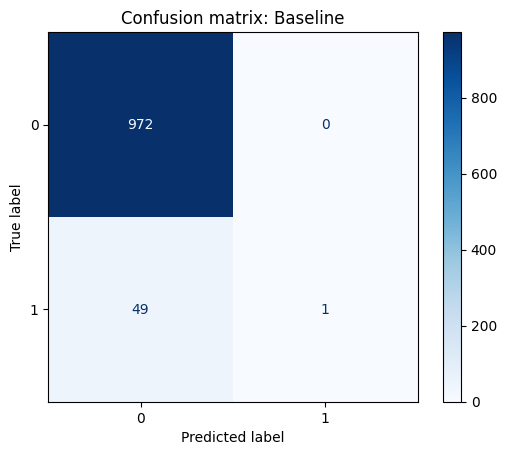

In [ ]:
ConfusionMatrixDisplay.from_estimator(baseline, X_test_s, y_test, cmap='Blues')
plt.title("Confusion matrix: Baseline")
plt.show()

{'Model': 'Balanced class weights', 'Accuracy': 0.739, 'Precision (stroke)': 0.135, 'Recall (stroke)': 0.8, 'F1 (stroke)': 0.231, 'ROC-AUC': np.float64(0.839)}

Classification report (Balanced):
              precision    recall  f1-score   support

           0       0.99      0.74      0.84       972
           1       0.13      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.81      1022



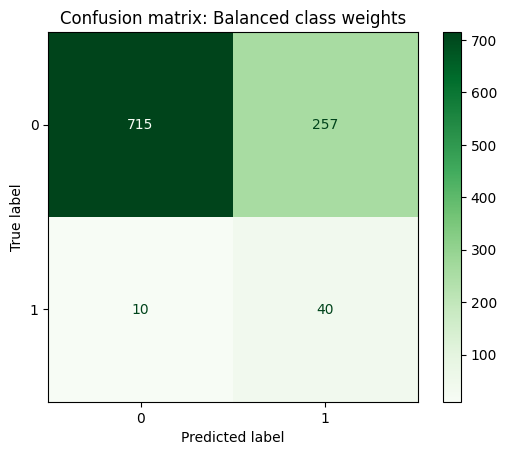

In [ ]:
balanced = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
balanced.fit(X_train_s, y_train)

results.append(evaluate("Balanced class weights", balanced, X_test_s, y_test))
print(results[-1])
print("\nClassification report (Balanced):")
print(classification_report(y_test, balanced.predict(X_test_s), zero_division=0))

ConfusionMatrixDisplay.from_estimator(balanced, X_test_s, y_test, cmap='Greens')
plt.title("Confusion matrix: Balanced class weights")
plt.show()

In [ ]:
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
                    param_grid, scoring='recall', cv=cv)
grid.fit(X_train_s, y_train)

print("Best parameters:", grid.best_params_)
print("Best cross-validated recall:", round(grid.best_score_, 3))

best_model = grid.best_estimator_
results.append(evaluate("Balanced + tuned (best C)", best_model, X_test_s, y_test))

Best parameters: {'C': 1}
Best cross-validated recall: 0.819


In [ ]:
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision (stroke),Recall (stroke),F1 (stroke),ROC-AUC
0,Baseline,0.952,1.000,0.02,0.039,0.839
1,Balanced class weights,0.739,0.135,0.80,0.231,0.839
2,Balanced + tuned (best C),0.739,0.135,0.80,0.231,0.839


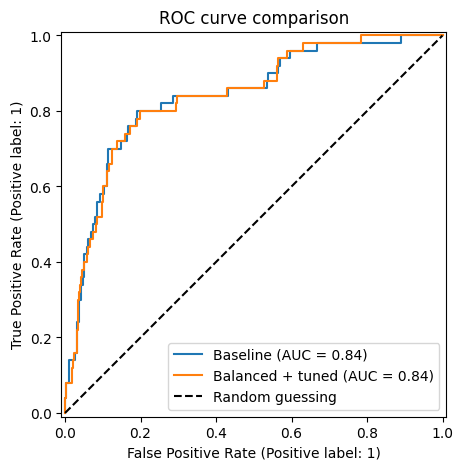

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_estimator(baseline, X_test_s, y_test, name="Baseline", ax=ax)
RocCurveDisplay.from_estimator(best_model, X_test_s, y_test, name="Balanced + tuned", ax=ax)
ax.plot([0, 1], [0, 1], 'k--', label="Random guessing")
ax.set_title("ROC curve comparison")
ax.legend()
plt.show()

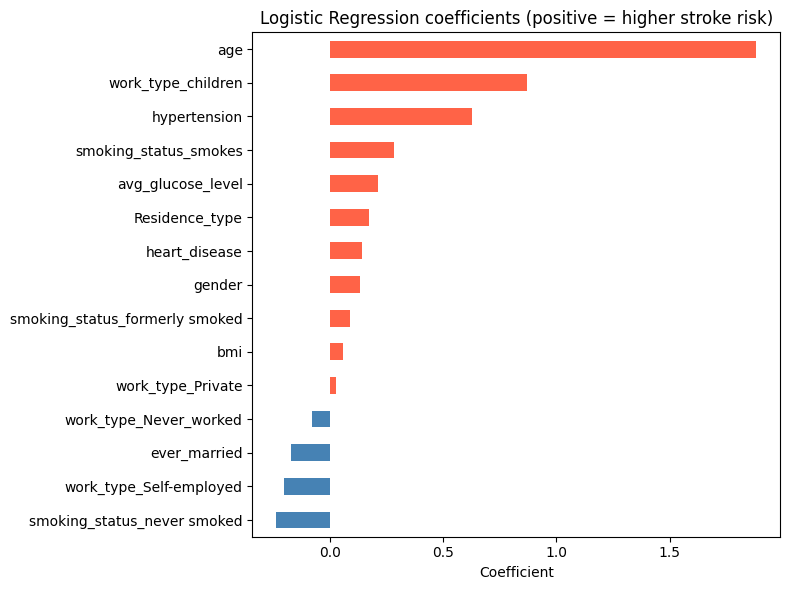

Top 5 risk-increasing features:
age                      1.882
work_type_children       0.869
hypertension             0.627
smoking_status_smokes    0.284
avg_glucose_level        0.212
dtype: float64


In [ ]:
coefs = pd.Series(best_model.coef_[0], index=X_train_s.columns).sort_values()

plt.figure(figsize=(8, 6))
coefs.plot(kind='barh', color=['tomato' if c > 0 else 'steelblue' for c in coefs])
plt.title("Logistic Regression coefficients (positive = higher stroke risk)")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()

print("Top 5 risk-increasing features:")
print(coefs.sort_values(ascending=False).head(5).round(3))

In [ ]:
df_enc.to_csv("stroke_cleaned.csv", index=False)
print("Saved stroke_cleaned.csv (download it from the Files panel on the left)")

Saved stroke_cleaned.csv (download it from the Files panel on the left)
